# Scaling up: 8-task multi-MNIST

Does our method still keep the tasks apart when there are many of them, and how close does it get to the ideal
connectivity? The experiment of `05_multi_mnist.ipynb`, scaled from 2 to 8 tasks with 10 hidden units per task.

**Problem.** As in `05_multi_mnist.ipynb`, with 8 tasks: each sample concatenates 8 independently drawn 14×14 MNIST
training images (per-pixel centered, one global scale), and each task's target is its own image's label. Every 250
steps, one task (chosen at random) gets a new random mapping from digits to labels, so each task changes about every
2000 steps, as in the 2-task problem. The loss is the sum of each task's softmax cross-entropy.

**Networks.** 1568 inputs → 80 LTU hidden units → 80 linear outputs (8 groups of 10 logits), each layer with a bias.
- *Fully connected*: every hidden unit reads every input and feeds every output.
- *Ideal connectivity*: 10 hidden units per task, each reading only its own task's image and feeding only its own task's
  logits.

**Learner.** Ours, as in `05_multi_mnist.ipynb`: centered hidden units with a matching centered backward pass, and input
weights starting at $U(-\alpha_0, \alpha_0)$, with $\alpha_0 = 10^{-8}$, meta step-size 0.01 and $\tau = 10^4$.

## Question 1: does our method keep the tasks apart at scale, and does simple generate and test help?

Three runs: the ideal connectivity, fully connected, and fully connected with the simple generate and test of
`05_multi_mnist.ipynb`, except that every 100k steps it resets the 4 hidden units with the smallest mean $|$output
weight$|$ at once (output weights 0, input weights $U(-\alpha_0, \alpha_0)$, step-sizes $\alpha_0$, zero Autostep traces,
running means at their initial values). 1M steps; seed $s$ gives every run the same initial-weight draw, images and
label changes.

**Hypotheses**, on the online accuracy (over every task) averaged over the last 10% of training, pooled over seeds:
- **H1**: fully connected is at most 1 percentage point below ideal connectivity.
- **H2**: generate and test helps: with it, the fully connected network is more than 1 percentage point above itself
  without it.

**Diagnostics**, fixed in advance: path purity and allocation over training, as in `05_multi_mnist.ipynb`. Allocation
is $(1 - \text{largest task's share of units}) / (1 - 1/8)$: 1 when every task has 10 units, 0 when all 80 feed one
task.

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from torchvision import datasets

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

sns.set_theme('notebook', 'white')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [8]:
# --- Problem ---
N_TASKS = 8
N_PIXELS = 14 * 14                   # MNIST downsampled from 28x28 by averaging 2x2 blocks
N_CLASSES = 10
PERMUTE_PERIOD = 2000 // N_TASKS     # steps between label changes, each of one task chosen at random

# --- Network ---
N_HIDDEN_PER_TASK = 10               # the ideal network's units per task; the fully connected one has as many in total

# --- Autostep ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means (used by ours)

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 30
N_WINDOWS = 500                      # each window records its mean loss, accuracy, path purity and allocation
BATCH = 15                           # networks trained at once; past about 20 they spill out of the GPU's cache and
                                     # every step gets several times slower

# --- Generate and test ---
RESET_PERIOD = 100_000               # steps between resets ...
N_RESET = 4                          # ... of this many hidden units at once, those with the lowest utility
SWEEP_SEEDS = 5                      # seeds per configuration in the sweeps (Questions 2 and 3)
UTILITY_PERIODS = (20_000, 50_000, 100_000)      # Question 2: reset periods ...
UTILITY_DECAYS = (0.999, 0.9999, 0.99999)        # ... and per-step decays of the utility traces

# --- Hypotheses ---
FINAL_FRACTION = 0.1                 # accuracy is compared over the last 10% of training ...
ACCURACY_TOLERANCE = 0.01            # ... with this tolerance (1 percentage point)

In [3]:
mnist = datasets.MNIST(root='/tmp/data', train=True, download=True)
images = np.asarray(mnist.data, dtype=np.float32).reshape(-1, 14, 2, 14, 2).mean((2, 4)).reshape(-1, N_PIXELS) / 255.0
IMAGES = jnp.asarray((images - images.mean(0)) / images.std())     # per-pixel centered, one global scale
DIGITS = jnp.asarray(np.asarray(mnist.targets))


class Stream(NamedTuple):
    key: jax.Array
    step: jax.Array
    label_maps: jax.Array     # (task, digit): each task's current label for each digit


def init_stream(key):
    return Stream(key, jnp.array(0), jnp.tile(jnp.arange(N_CLASSES), (N_TASKS, 1)))


def next_sample(stream):
    # One sample: an independent training image per task, concatenated, and each task's label. Every PERMUTE_PERIOD
    # steps, one task chosen at random first gets a new random label mapping.
    key, task_key, map_key, image_key = jax.random.split(stream.key, 4)
    step = stream.step + 1
    changes = (step % PERMUTE_PERIOD == 0) & (jnp.arange(N_TASKS) == jax.random.randint(task_key, (), 0, N_TASKS))
    label_maps = jnp.where(changes[:, None], jax.random.permutation(map_key, N_CLASSES)[None], stream.label_maps)
    index = jax.random.randint(image_key, (N_TASKS,), 0, IMAGES.shape[0])
    labels = label_maps[jnp.arange(N_TASKS), DIGITS[index]]
    return Stream(key, step, label_maps), (IMAGES[index].reshape(-1), labels)

In [4]:
LAYERS = ('w1', 'w2')

input_task = np.repeat(np.arange(N_TASKS), N_PIXELS)
hidden_task = np.repeat(np.arange(N_TASKS), N_HIDDEN_PER_TASK)
output_task = np.repeat(np.arange(N_TASKS), N_CLASSES)


def with_bias_column(mask, bias):
    # The last column of each weight matrix reads the constant-1 input.
    return np.concatenate([mask, np.full((mask.shape[0], 1), bias)], axis=1)


# Masks are shaped like the weight matrices: w1 is (hidden, inputs + 1), w2 is (outputs, hidden + 1).
same_task = {'w1': hidden_task[:, None] == input_task[None, :],
             'w2': output_task[:, None] == hidden_task[None, :]}
MASKS = {'ideal connectivity': {k: with_bias_column(m, True) for k, m in same_task.items()},
         'fully connected': {k: np.ones((m.shape[0], m.shape[1] + 1), bool) for k, m in same_task.items()}}

for name, masks in MASKS.items():
    print(f'{name}: ' + ', '.join(f'{k} {masks[k][:, :-1].sum():,} weights' for k in LAYERS))

ideal connectivity: w1 15,680 weights, w2 800 weights
fully connected: w1 125,440 weights, w2 6,400 weights


## Learner

In [11]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Learner(NamedTuple):
    w: dict                   # {'w1': ..., 'w2': ...}; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState
    hidden_mean: jax.Array    # each hidden unit's running mean firing rate
    hidden_slope: jax.Array   # running mean of sigma'(z) x, each hidden unit's derivative w.r.t. each input weight
    pair: jax.Array           # each hidden unit's output for shadow feedback (Question 3) ...
    sign: jax.Array           # ... and its fixed +-1 shadow weight from that output


def init_learner(key, masks, ours):
    # Input weights: U(-INIT_STEP_SIZE, INIT_STEP_SIZE) for ours, LeCun uniform over each unit's inputs otherwise. Both
    # scale the same draw.
    fan_in = masks['w1'][:, :-1].sum(1, keepdims=True)
    bound = INIT_STEP_SIZE if ours else np.sqrt(3.0 / fan_in)
    w1 = jax.random.uniform(key, masks['w1'].shape, minval=-1.0, maxval=1.0) * bound * masks['w1']
    w = {'w1': w1.at[:, -1].set(0.0), 'w2': jnp.zeros(masks['w2'].shape)}
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs, 1/4 for the bias.
    n_hidden, n_outputs = masks['w1'].shape[0], masks['w2'].shape[0]
    pair = jax.random.randint(jax.random.fold_in(key, 1), (n_hidden,), 0, n_outputs)
    sign = jax.random.rademacher(jax.random.fold_in(key, 2), (n_hidden,), dtype=jnp.float32)
    return Learner(w, OPTIMIZER.init(w), jnp.full(n_hidden, 0.5), jnp.zeros(masks['w1'].shape).at[:, -1].set(0.25),
                   pair, sign)


def forward(w, x, learner, masks, ours, shadow=False):
    # Returns the prediction, each weight's source values (what Autostep normalizes by), and the new running means.
    x = jnp.append(x, 1.0)
    w1 = w['w1'] * masks['w1']
    z = w1 @ x
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = learner.hidden_mean + EMA_RATE * (jax.lax.stop_gradient(h) - learner.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))     # the LTU's surrogate slope
    slope = learner.hidden_slope + EMA_RATE * (sigma_prime[:, None] * x[None, :] - learner.hidden_slope)
    if ours:
        # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
        # correction leaves the value unchanged.
        correction = jnp.sum(slope * w1, axis=1)
        h = h - mean - correction + jax.lax.stop_gradient(correction)

    w2 = w['w2'] * masks['w2']
    if not shadow:
        y_hat = w2 @ jnp.append(h, 1.0)
    else:
        # Shadow feedback (Question 3): the outputs read h as usual, but h's gradient comes through a fixed matrix: the
        # output weights, except that the weight from each unit's paired output counts as its +-1 shadow weight unless
        # the real one is larger in magnitude. The last two terms cancel in value, and the output weights keep their
        # true gradient.
        units = jnp.arange(h.shape[0])
        paired = w2[learner.pair, units]
        feedback = jax.lax.stop_gradient(
            w2[:, :-1].at[learner.pair, units].set(jnp.where(jnp.abs(paired) > 1.0, paired, learner.sign)))
        y_hat = w2 @ jnp.append(jax.lax.stop_gradient(h), 1.0) + feedback @ h - jax.lax.stop_gradient(feedback @ h)
    return y_hat, ({'w1': x[None], 'w2': jnp.append(h, 1.0)[None]}, mean, slope)


def learner_step(learner, x, labels, masks, ours, shadow=False):
    # One online Autostep update on the summed softmax cross-entropy of every task. Returns the new learner, the loss,
    # the fraction of tasks classified correctly, and what the hidden units sent.
    def loss_fn(w):
        logits, aux = forward(w, x, learner, masks, ours, shadow)
        logits = logits.reshape(N_TASKS, N_CLASSES)
        return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), (aux, logits)

    (loss, ((source_values, mean, slope), logits)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    updates, opt = OPTIMIZER.update((grads, None, source_values), learner.opt, learner.w)
    w = {k: learner.w[k] + updates[k] for k in LAYERS}
    learner = learner._replace(w=w, opt=opt, hidden_mean=mean, hidden_slope=slope)
    return learner, loss, jnp.mean(logits.argmax(-1) == labels), source_values['w2'][0, :-1]

## Training

In [12]:
WINDOW = NUM_STEPS // N_WINDOWS      # steps per window


def path_purity(w):
    # The share of all input -> hidden -> output path weight (the product of |w| along the path) that starts and ends
    # in the same task. Biases are left out.
    n_hidden = w['w1'].shape[0]
    reads = jnp.abs(w['w1'][:, :-1]).reshape(n_hidden, N_TASKS, N_PIXELS).sum(-1)      # (unit, task)
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, N_CLASSES, n_hidden).sum(1).T    # (unit, task)
    return jnp.sum(reads * feeds) / jnp.maximum(jnp.sum(reads.sum(-1) * feeds.sum(-1)), 1e-30)


def allocation(w):
    # How evenly the hidden units are split between the tasks, counting each unit for the task whose outputs it feeds
    # most: 1 when every task has the same number, 0 when all units feed one task.
    n_hidden = w['w1'].shape[0]
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, N_CLASSES, n_hidden).sum(1)      # (task, unit)
    largest = jnp.max(jnp.bincount(feeds.argmax(0), length=N_TASKS)) / n_hidden
    return (1 - largest) / (1 - 1 / N_TASKS)


def reset_units(learner, units, key, masks):
    # The hidden units marked in `units` start over as new units: their weights, step-sizes, Autostep traces and running
    # means are set to those of a freshly initialized network (output weights 0, input weights
    # U(-INIT_STEP_SIZE, INIT_STEP_SIZE)).
    fresh = init_learner(key, masks, ours=True)
    parts = {'w1': units[:, None], 'w2': jnp.append(units, False)[None, :]}         # their rows of w1, columns of w2
    pick = lambda new, old: {k: jnp.where(parts[k], new[k], old[k]) for k in LAYERS}
    opt = learner.opt
    return learner._replace(
        w=pick(fresh.w, learner.w),
        opt=opt._replace(beta=pick(fresh.opt.beta, opt.beta), h=pick(fresh.opt.h, opt.h), v=pick(fresh.opt.v, opt.v)),
        hidden_mean=jnp.where(units, fresh.hidden_mean, learner.hidden_mean),
        hidden_slope=jnp.where(units[:, None], fresh.hidden_slope, learner.hidden_slope),
        pair=jnp.where(units, fresh.pair, learner.pair), sign=jnp.where(units, fresh.sign, learner.sign))


def train(key, stream, masks, ours, reset_period=None, decay=None, shadow=False):
    # Step 1 on its own, then NUM_STEPS online steps in windows. With `reset_period` (a multiple of WINDOW), generate
    # and test runs at the end of every window that ends on a multiple of it: the N_RESET hidden units with the lowest
    # utility start over as new units. A unit's utility is its mean |output weight| (simple generate and test, `decay`
    # None), or a trace of |h| (what it sent) times the sum of its |output weights|, decaying by `decay` per step,
    # where a new unit's trace starts at the median of all units'. With `shadow`, hidden units learn through shadow
    # feedback (see forward()). Returns the mean loss and accuracy of every window, and the path purity and allocation
    # at its end.
    def one_step(carry, _):
        learner, stream, trace = carry
        stream, (x, labels) = next_sample(stream)
        learner, loss, accuracy, h = learner_step(learner, x, labels, masks, ours, shadow)
        if decay is not None:
            trace = decay * trace + (1 - decay) * jnp.abs(h) * jnp.abs(learner.w['w2'][:, :-1]).sum(0)
        return (learner, stream, trace), (loss, accuracy)

    def window(carry, index):
        (learner, stream, trace), (loss, accuracy) = jax.lax.scan(one_step, carry, length=WINDOW)
        if reset_period is not None:
            utility = jnp.abs(learner.w['w2'][:, :-1]).mean(0) if decay is None else trace
            units = jnp.argsort(jnp.argsort(utility)) < N_RESET                  # the N_RESET lowest
            due = (index + 1) * WINDOW % reset_period == 0
            reset = reset_units(learner, units, jax.random.fold_in(key, index), masks)
            learner = jax.tree.map(lambda new, old: jnp.where(due, new, old), reset, learner)
            trace = jnp.where(due & units, jnp.median(trace), trace)
        w = learner.w
        return (learner, stream, trace), {'loss': loss.mean(), 'accuracy': accuracy.mean(), 'purity': path_purity(w),
                                          'allocation': allocation(w)}

    stream, (x, labels) = next_sample(stream)
    learner = learner_step(init_learner(key, masks, ours), x, labels, masks, ours, shadow)[0]
    trace = jnp.zeros(learner.hidden_mean.shape)
    return jax.lax.scan(window, (learner, stream, trace), jnp.arange(N_WINDOWS))[1]


def seeds(n):
    # The first n seeds' init keys and streams. Seed s uses init key s and stream s in every run, so runs are paired.
    keys = jax.random.split(jax.random.PRNGKey(0), N_SEEDS)[:n]
    return keys, jax.vmap(init_stream)(jax.random.split(jax.random.PRNGKey(1), N_SEEDS)[:n])


def batched(fn, *args):
    # `fn` vmapped over the leading axis of every argument and jitted, run on BATCH entries at a time. Returns the
    # concatenated results as numpy arrays.
    f = jax.jit(jax.vmap(fn))
    n = len(jax.tree.leaves(args)[0])
    chunks = [f(*jax.tree.map(lambda a: a[i:i + BATCH], args)) for i in range(0, n, BATCH)]
    return jax.tree.map(lambda *c: np.concatenate(c), *chunks)


def run(network, ours, reset_period=None, decay=None):
    # Trains our learner (or standard Autostep) on `network` (a key of MASKS) on every seed, with generate and test as
    # in train(). Returns per-seed records: loss, accuracy, purity and allocation (seed, window).
    return batched(lambda key, stream: train(key, stream, MASKS[network], ours, reset_period, decay), *seeds(N_SEEDS))


def sweep(periods, decays, shadow=False):
    # Fully connected, our learner with generate and test by utility traces, for every (reset period, decay) pair on the
    # first SWEEP_SEEDS seeds, with or without shadow feedback. Returns records shaped (period, decay, seed, window).
    grid = [(p, d) for p in periods for d in decays]
    keys, streams = seeds(SWEEP_SEEDS)
    tile = lambda a: jnp.tile(a, (len(grid),) + (1,) * (a.ndim - 1))
    period = jnp.repeat(jnp.array([p for p, _ in grid]), SWEEP_SEEDS)
    decay = jnp.repeat(jnp.array([d for _, d in grid], dtype=jnp.float32), SWEEP_SEEDS)
    records = batched(lambda key, stream, p, d: train(key, stream, MASKS['fully connected'], True, p, d, shadow),
                      tile(keys), jax.tree.map(tile, streams), period, decay)
    return jax.tree.map(lambda a: a.reshape(len(periods), len(decays), SWEEP_SEEDS, *a.shape[1:]), records)

## Results

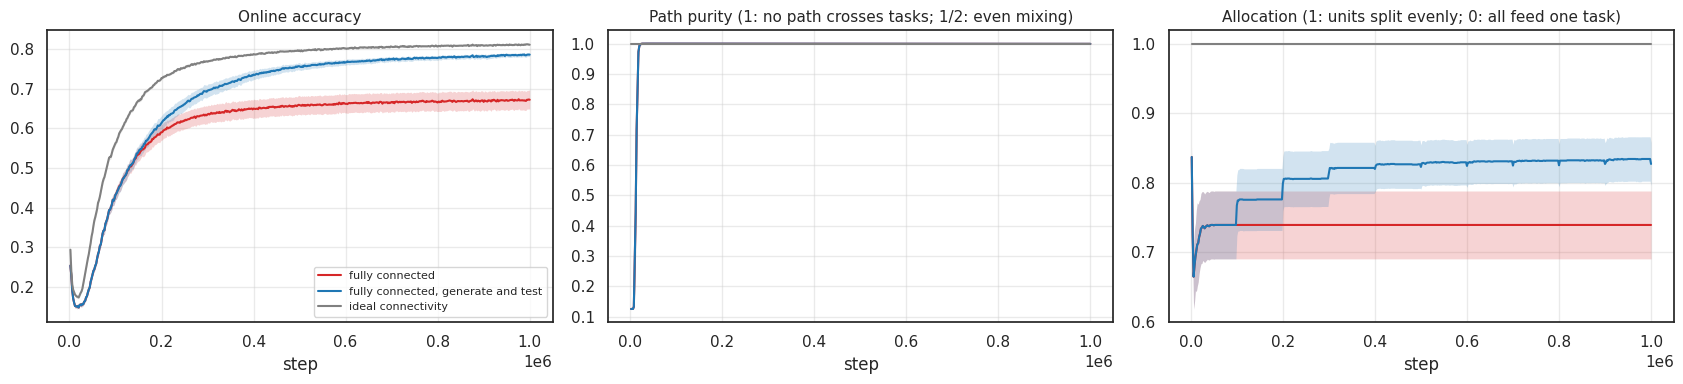

fully connected                      online accuracy 67.02%
fully connected, generate and test   online accuracy 78.34%
ideal connectivity                   online accuracy 80.97%
H1, fully connected vs ideal connectivity: -14.0 points (± 2.4): failed
H2, fully connected vs fully connected, generate and test: -11.3 points (± 2.0): held


In [7]:
window_ends = np.arange(1, N_WINDOWS + 1) * (NUM_STEPS // N_WINDOWS)
final = slice(-round(N_WINDOWS * FINAL_FRACTION), None)


def plot_runs(runs, colors, dashed=()):
    # Accuracy, path purity and allocation over training for each run in `runs` (mean +- 2 SE over seeds), drawn in
    # `colors[label]`, and dashed for the labels in `dashed`.
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    for ax, (key, title) in zip(axes, [('accuracy', 'Online accuracy'),
                                       ('purity', 'Path purity (1: no path crosses tasks; 1/2: even mixing)'),
                                       ('allocation', 'Allocation (1: units split evenly; 0: all feed one task)')]):
        for label, res in runs.items():
            mean, sem = res[key].mean(0), res[key].std(0) / np.sqrt(N_SEEDS)
            ax.plot(window_ends, mean, color=colors[label], ls='--' if label in dashed else '-', lw=1.5, label=label)
            ax.fill_between(window_ends, mean - 2 * sem, mean + 2 * sem, color=colors[label], alpha=0.2, lw=0)
        ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
        ax.set_xlabel('step')
        ax.set_title(title, fontsize=11)
        ax.grid(alpha=0.4)
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()


def final_accuracy(res):
    return res['accuracy'][:, final].mean(1)                 # each seed's accuracy over the last FINAL_FRACTION


def report(runs, tests):
    # Prints every run's accuracy, then for each test (name, label, reference, claim) the per-seed gap of `label` to
    # `reference` (mean and 2 SE over paired seeds), and whether the claim held: 'within' ACCURACY_TOLERANCE of it, or
    # more than that 'below' it (no claim: None).
    width = max(map(len, runs))
    for label, res in runs.items():
        print(f'{label:<{width}}   online accuracy {final_accuracy(res).mean():.2%}')
    for name, label, reference, claim in tests:
        g = final_accuracy(runs[label]) - final_accuracy(runs[reference])
        ok = g.mean() >= -ACCURACY_TOLERANCE if claim == 'within' else g.mean() < -ACCURACY_TOLERANCE
        verdict = '' if claim is None else f': {"held" if ok else "failed"}'
        print(f'{name}, {label} vs {reference}: {100 * g.mean():+.1f} points '
              f'(± {100 * 2 * g.std() / np.sqrt(N_SEEDS):.1f}){verdict}')


runs = {'fully connected': run('fully connected', True),
        'fully connected, generate and test': run('fully connected', True, reset_period=RESET_PERIOD),
        'ideal connectivity': run('ideal connectivity', True)}
plot_runs(runs, {'fully connected': 'tab:red', 'fully connected, generate and test': 'tab:blue',
                 'ideal connectivity': 'gray'})
report(runs, [('H1', 'fully connected', 'ideal connectivity', 'within'),
              ('H2', 'fully connected', 'fully connected, generate and test', 'below')])

## Results

- **H1 failed.** Fully connected, our method reaches 67.0% online accuracy against 81.0% with the ideal connectivity:
  −14.0 points (± 2.4, 2 SE over paired seeds), far more than with 2 tasks (−5.0).
- **H2 held.** The simple generate and test lifts it to 78.3%, +11.3 points (± 2.0), leaving 2.6 points to the ideal
  network, and it is still rising at 1M steps.
- **Diagnostics.** Path purity reaches 1 within about 20k steps in every run: even with 8 tasks, our method never mixes
  them. The shortfall is allocation again. Without generate and test, allocation settles at about 0.74 within the first
  20k steps and never changes; with it, allocation climbs in a step at each reset, mostly at the first three (100k to
  300k steps), to about 0.83.

## Question 2: does generate and test with utility traces improve over the simple version?

The tester of `05_multi_mnist.ipynb`'s earlier utility-trace version (after Mahmood and Sutton, 2013): each hidden unit
keeps a trace, starting at 0, of its instantaneous utility $|h_j - m_j| \sum_o |w_{oj}|$ (what it sends times the summed
magnitudes of its output weights). Every step the trace decays by a factor $\lambda$ and adds $(1 - \lambda)$ times the
utility. Every reset period, the 4 units with the lowest traces start over as new units (as in Question 1), and their
traces are set to the median over all units, which gives them room before they can be picked again. Swept: reset
period 20k, 50k and 100k steps × decay $\lambda$ 0.999, 0.9999 and 0.99999 (traces that remember about the last 1k, 10k
and 100k steps), on the first 5 seeds of Question 1. Each point is the accuracy or allocation over the last 10% of
training (mean $\pm$ 2 SE over seeds), against Question 1's simple generate and test and ideal connectivity on the same
5 seeds.

**H3**: the best configuration of the grid (highest mean accuracy over the last 10% of training) is more than 1
percentage point above the simple generate and test on the same seeds. Picking the best of 9 configurations favours the
grid somewhat.

**Diagnostics**, fixed in advance: allocation for every configuration.

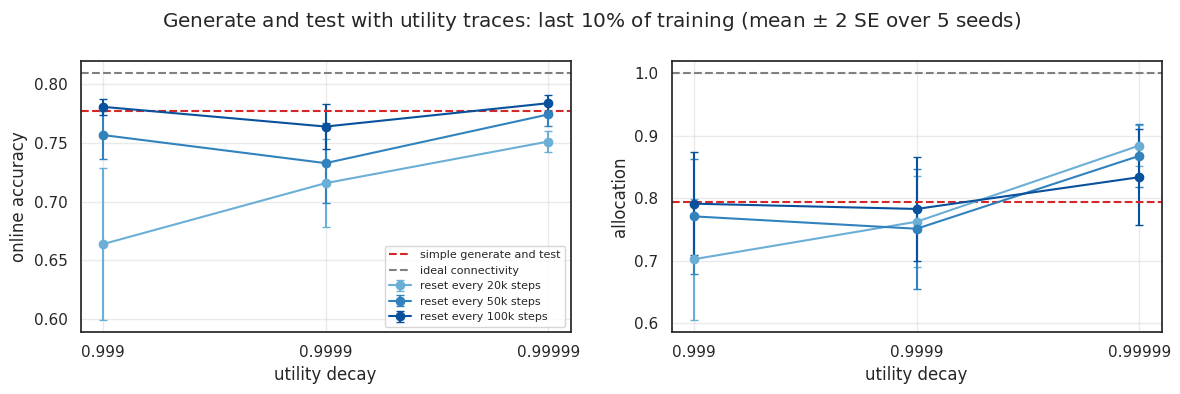

reset every  20,000 steps, decay 0.999  : accuracy 66.37%, allocation 0.70
reset every  20,000 steps, decay 0.9999 : accuracy 71.57%, allocation 0.76
reset every  20,000 steps, decay 0.99999: accuracy 75.13%, allocation 0.88
reset every  50,000 steps, decay 0.999  : accuracy 75.68%, allocation 0.77
reset every  50,000 steps, decay 0.9999 : accuracy 73.28%, allocation 0.75
reset every  50,000 steps, decay 0.99999: accuracy 77.44%, allocation 0.87
reset every 100,000 steps, decay 0.999  : accuracy 78.09%, allocation 0.79
reset every 100,000 steps, decay 0.9999 : accuracy 76.40%, allocation 0.78
reset every 100,000 steps, decay 0.99999: accuracy 78.40%, allocation 0.83
simple generate and test on these seeds: 77.71%
H3, best (reset every 100k steps, decay 0.99999) vs simple generate and test: +0.7 points (± 1.0): failed


In [10]:
grid = sweep(UTILITY_PERIODS, UTILITY_DECAYS)
seeds_ = slice(None, SWEEP_SEEDS)                               # Question 1's runs on the sweep's seeds
references = {'simple generate and test': runs['fully connected, generate and test'],
              'ideal connectivity': runs['ideal connectivity']}


def plot_grid(grid, title):
    # Accuracy and allocation over the last FINAL_FRACTION of training against the decay, one line per reset period,
    # with Question 1's simple generate and test and ideal connectivity on the same seeds.
    memory = [1 / (1 - d) for d in UTILITY_DECAYS]                 # about how many steps each trace remembers
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, (key, ylabel) in zip(axes, [('accuracy', 'online accuracy'), ('allocation', 'allocation')]):
        for i, (p, color) in enumerate(zip(UTILITY_PERIODS, ('#6baed6', '#3182bd', '#08519c'))):
            v = grid[key][i][..., final].mean(-1)                   # (decay, seed)
            ax.errorbar(memory, v.mean(1), yerr=2 * v.std(1) / np.sqrt(SWEEP_SEEDS), color=color, marker='o', lw=1.5,
                        capsize=3, label=f'reset every {p // 1000}k steps')
        for (label, res), color in zip(references.items(), ('tab:red', 'gray')):
            ax.axhline(res[key][seeds_, final].mean(), color=color, lw=1.5, ls='--', label=label)
        ax.set_xscale('log')
        ax.set_xticks(memory, [f'{d:g}' for d in UTILITY_DECAYS])
        ax.set_xlabel('utility decay')
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.4)
    axes[0].legend(fontsize=8)
    fig.suptitle(f'{title}: last 10% of training (mean $\\pm$ 2 SE over {SWEEP_SEEDS} seeds)')
    fig.tight_layout()
    plt.show()


def best_of(grid):
    # The configuration with the highest mean accuracy over the last FINAL_FRACTION of training: its label and records.
    i, j = np.unravel_index(grid['accuracy'][..., final].mean((-1, -2)).argmax(), grid['accuracy'].shape[:2])
    return (f'reset every {UTILITY_PERIODS[i] // 1000}k steps, decay {UTILITY_DECAYS[j]:g}',
            {k: v[i, j] for k, v in grid.items()})


plot_grid(grid, 'Generate and test with utility traces')
for i, p in enumerate(UTILITY_PERIODS):
    for j, d in enumerate(UTILITY_DECAYS):
        print(f'reset every {p:>7,} steps, decay {d:<7g}: accuracy {grid["accuracy"][i, j][:, final].mean():.2%}, '
              f'allocation {grid["allocation"][i, j][:, final].mean():.2f}')
label, best = best_of(grid)
simple = final_accuracy({k: v[seeds_] for k, v in references['simple generate and test'].items()})
g = final_accuracy(best) - simple
print(f'simple generate and test on these seeds: {simple.mean():.2%}')
print(f'H3, best ({label}) vs simple generate and test: {100 * g.mean():+.1f} points '
      f'(± {100 * 2 * g.std() / np.sqrt(SWEEP_SEEDS):.1f}): {"held" if g.mean() > ACCURACY_TOLERANCE else "failed"}')

**Result: H3 failed.** The best configuration, resets every 100k steps with decay 0.99999, reaches 78.4% online
accuracy, +0.7 points (± 1.0) above the simple generate and test on the same 5 seeds (77.7%). Longer reset periods are
better at every decay, and the longest-memory traces (0.99999) are the best decay at every period; at 100k steps the
decay matters little (76.4–78.4%). Long-memory traces even out the split the most (allocation 0.83–0.88, against
0.70–0.79 otherwise), but frequent resets cost accuracy: at 20k steps the best allocation of the grid (0.88) comes with
only 75.1%, and short-memory traces with frequent resets do worst (66.4% at 20k steps and decay 0.999). As with 2
tasks, the best period is the longest one tried.

## Question 3: do shadow weights make the search faster?

Question 2's sweep again, with shadow feedback. Each hidden unit is paired with a random output and given a random
shadow weight of $+1$ or $-1$, both drawn again whenever the unit is reset. In the backward pass a unit hears from every
output through the output weights, as in backprop, except that the weight from its paired output counts as its shadow
weight unless the real one is larger in magnitude. The forward pass is unchanged and the output weights keep their true
gradients. A new unit starts with output weights at 0, so without shadow feedback its input weights get no gradient
until its output weights grow; the shadow weight gives them one from the start. The pairing is random, so unlike
`shadow_feedback.ipynb` (unit $j$ with output $j$) it does not build in an even split.

**H4**: the best configuration with shadow feedback is more than 1 percentage point above the best configuration
without it (Question 2), over the last 10% of training on the same 5 seeds.

**Diagnostics**, fixed in advance: allocation for every configuration; and for the two best configurations, the mean
accuracy over all of training (a measure of speed) and accuracy over training, against Question 1's simple generate and
test and ideal connectivity on the same seeds.

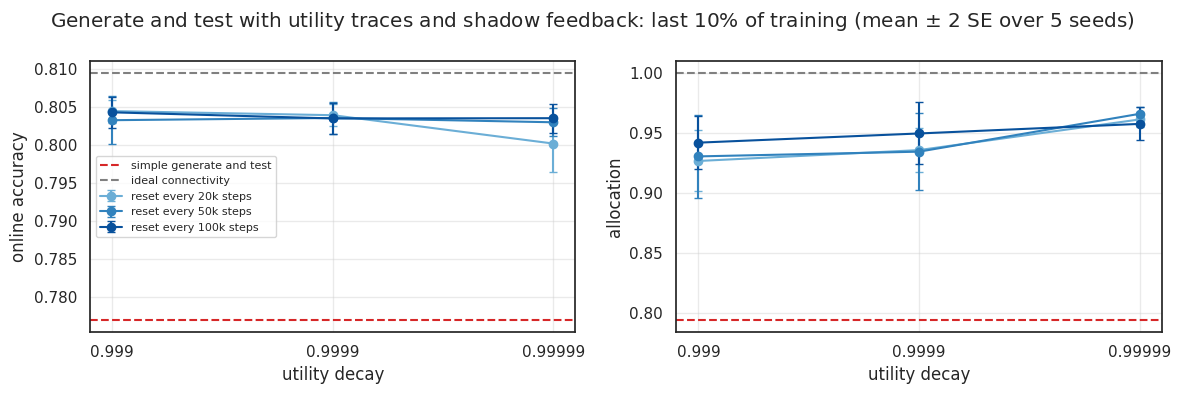

reset every  20,000 steps, decay 0.999  : accuracy 80.45%, allocation 0.93
reset every  20,000 steps, decay 0.9999 : accuracy 80.40%, allocation 0.94
reset every  20,000 steps, decay 0.99999: accuracy 80.02%, allocation 0.96
reset every  50,000 steps, decay 0.999  : accuracy 80.33%, allocation 0.93
reset every  50,000 steps, decay 0.9999 : accuracy 80.36%, allocation 0.93
reset every  50,000 steps, decay 0.99999: accuracy 80.30%, allocation 0.97
reset every 100,000 steps, decay 0.999  : accuracy 80.43%, allocation 0.94
reset every 100,000 steps, decay 0.9999 : accuracy 80.35%, allocation 0.95
reset every 100,000 steps, decay 0.99999: accuracy 80.36%, allocation 0.96


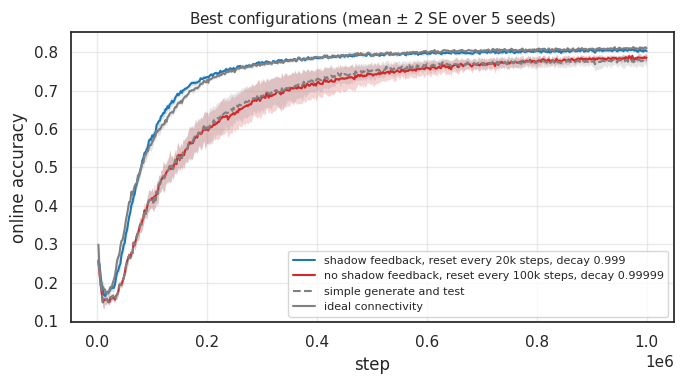

shadow feedback, reset every 20k steps, decay 0.999         accuracy over the last 10% 80.45%, over all of training 73.55%
no shadow feedback, reset every 100k steps, decay 0.99999   accuracy over the last 10% 78.40%, over all of training 67.10%
simple generate and test                                    accuracy over the last 10% 77.71%, over all of training 67.37%
ideal connectivity                                          accuracy over the last 10% 80.95%, over all of training 73.63%
H4, best with shadow feedback vs best without: +2.1 points (± 0.6): held


In [13]:
shadow_grid = sweep(UTILITY_PERIODS, UTILITY_DECAYS, shadow=True)
plot_grid(shadow_grid, 'Generate and test with utility traces and shadow feedback')
for i, p in enumerate(UTILITY_PERIODS):
    for j, d in enumerate(UTILITY_DECAYS):
        print(f'reset every {p:>7,} steps, decay {d:<7g}: accuracy {shadow_grid["accuracy"][i, j][:, final].mean():.2%}, '
              f'allocation {shadow_grid["allocation"][i, j][:, final].mean():.2f}')

shadow_label, shadow_best = best_of(shadow_grid)
curves = {f'shadow feedback, {shadow_label}': shadow_best, f'no shadow feedback, {label}': best,
          **{name: {k: v[seeds_] for k, v in res.items()} for name, res in references.items()}}
fig, ax = plt.subplots(figsize=(7, 4))
for (name, res), (color, ls) in zip(curves.items(), [('tab:blue', '-'), ('tab:red', '-'), ('gray', '--'), ('gray', '-')]):
    mean, sem = res['accuracy'].mean(0), res['accuracy'].std(0) / np.sqrt(SWEEP_SEEDS)
    ax.plot(window_ends, mean, color=color, ls=ls, lw=1.5, label=name)
    ax.fill_between(window_ends, mean - 2 * sem, mean + 2 * sem, color=color, alpha=0.2, lw=0)
ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
ax.set_xlabel('step')
ax.set_ylabel('online accuracy')
ax.set_title(f'Best configurations (mean $\\pm$ 2 SE over {SWEEP_SEEDS} seeds)', fontsize=11)
ax.grid(alpha=0.4)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

width = max(map(len, curves))
for name, res in curves.items():
    print(f'{name:<{width}}   accuracy over the last 10% {final_accuracy(res).mean():.2%}, '
          f'over all of training {res["accuracy"].mean():.2%}')
g = final_accuracy(shadow_best) - final_accuracy(best)
print(f'H4, best with shadow feedback vs best without: {100 * g.mean():+.1f} points '
      f'(± {100 * 2 * g.std() / np.sqrt(SWEEP_SEEDS):.1f}): {"held" if g.mean() > ACCURACY_TOLERANCE else "failed"}')

**Result: H4 held.** With shadow feedback, the best configuration (resets every 20k steps, decay 0.999) reaches
80.5% online accuracy, +2.1 points (± 0.6) above the best configuration without it (78.4%) and 0.5 points below the
ideal connectivity on the same seeds (81.0%). Every configuration of the grid lands within 80.0–80.5%, so the reset
period and decay barely matter, and allocation is 0.93–0.97 throughout (0.70–0.88 without shadow feedback). Learning is
also much faster: averaged over all of training, accuracy is 73.6%, the same as the ideal network's (73.6%), against
67.1% for the best configuration without shadow feedback, and the learning curve follows the ideal network's from the
start. Because the grid's settings barely matter, it is not shown how much of this comes from the search rather than
from shadow feedback alone: there is no shadow-feedback run without generate and test.